# M01 correcciones gravimétricas: cálculo trazable

**Pregunta:** ¿Cómo cambian la referencia WGS84 y la placa infinita el valor de estación definido, y cuánto altera la política de incertidumbre la desviación estándar informada?

**Nivel 2 · Prerrequisitos: la lección previa de fundamentos; lectura estimada: 55 minutos.**

## Objetivos

Ejecutar transformación M01, inspeccionar incrementos, probar políticas de incertidumbre y verificar rechazo de estado duplicado.

## Preparación

Use el entorno Python 3.12 fijado. Créelo desde la raíz con `scripts/setup.ps1 -Notebooks` en Windows o `scripts/setup.sh --notebooks` en Linux/macOS. El comando se documenta como referencia; el notebook no instala paquetes.

```text
pip install boule==0.5.0 harmonica==0.7.0
```

Importar una vez el método y herramientas gráficas. La celda informa implementación activa.

In [1]:
# Importe el pipeline M01 y las herramientas gráficas.
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
from gravity_processing import process_survey
from importlib.metadata import version
print('Boule:', version('boule'), '| Harmonica:', version('harmonica'))
print('Flujo de procesamiento:', Path(process_survey.__code__.co_filename).name)


Boule: 0.5.0 | Harmonica: 0.7.0
Flujo de procesamiento: gravity_processing.py


## Datos

La lección lee el control analítico de una estación en `docs/methods/gravity-processing/examples/station-control.json`. CAOS_Geophysics creó el synthetic_control bajo Apache-2.0; la cita de fuente registra los parámetros. El pipeline nombrado es `data-pipeline/gravity_processing.py`, con Boule y Harmonica. El control usa WGS84, metros elipsoidales, tide-free y gravedad absoluta positiva hacia abajo en mGal. Su residual de 12 mGal es analítico, no medido.

Leer entradas declaradas o construir geometría sintética propia. No se carga salida de solver.

In [2]:
# Leer control analítico versionado y conservar metadatos de procedencia.
from copy import deepcopy
import json
control_path = root / 'docs/methods/gravity-processing/examples/station-control.json'
request = json.loads(control_path.read_text(encoding='utf-8'))
source = request['dataset']
config = request['config']
print(source['metadata']['source_kind'], source['metadata']['rights'])
print(source['metadata']['height_datum'], source['metadata']['gravity_unit'])


synthetic_control Authored numerical control, Apache-2.0
ellipsoidal mGal


## Método

### Admitir la fuente declarada

El procesador valida esquema, coordenadas, unidades, signo, elipsoide, datum, estado instrumental y digest antes de cambiar valores. Esa validación integra el método: sin ella la corrección es indeterminada. Esta entrada analítica marca calibración aplicada y deriva/mareas no aplicables. Una importación de campo sin calibración conocida debe rechazarse, no normalizarse por conjetura.

### Establecer la perturbación de referencia

La etapa evalúa gravedad normal WGS84 para latitud y altura declaradas, y forma observada menos normal bajo convención canónica positiva hacia abajo. Boule implementa γ(φ,h). La elevación del receptor es 1000 m; no equivale a retirar una placa de 1000 m. La referencia y datum vertical pueden causar offsets que parecen geología.

### Aplicar el término de placa

La configuración declara objetivo `bouguer_disturbance`, densidad 2670 kg/m³, SD de densidad 20 kg/m³ y política `conservative_marginals`. El procesador calcula placa horizontal infinita y registra su incremento. Supone densidad homogénea y extensión lateral infinita; no es corrección DEM de terreno. Harmonica documenta la placa y el producto aporta admisión, signos, incertidumbre y linaje.

### Comparar políticas de incertidumbre

Las políticas admitidas agregan de modo distinto contribuciones marginales de primer orden. Son cálculos condicionales, no confianza empírica. Repetir con `independent_first_order` cambia solo agregación; fuente y corrección física permanecen fijas. La incertidumbre de densidad afecta la placa. No se modelan correlación ni datum, así que la desviación debe conservar su etiqueta.

### Desafiar la máquina de estados

El dataset corregido conserva estado e historial ordenado. La API debe rechazar una segunda pasada desde un estado derivado porque aplicaría referencia o placa dos veces. Este control negativo verifica el contrato. El rechazo es científicamente útil: una solicitud repetible no puede convertir silenciosamente una anomalía válida en magnitud sesgada.

### Interpretar con límites

El gráfico de incrementos y la comparación provienen de llamadas reales a `process_survey`. Revise compatibilidad con residual analítico de 12 mGal e historial de tres operaciones. El acuerdo prueba aritmética y convenciones únicamente. No evalúa completitud del levantamiento, terreno, instrumentos, campo regional ni geología.

### La incertidumbre sigue siendo condicional

La propagación de primer orden deriva la magnitud respecto de errores especificados. Omite correlación desconocida, error de modelo, placa finita, terreno, conversión de datum y selección de fuente. Elegir el número menor porque parece más preciso no es un análisis válido.

### Derivadas de incertidumbre y unidades

Para q(x), la propagación de primer orden aproxima Var(q) usando covarianza de entrada y gradiente de q. El procesador separa aportes de gravedad, latitud, alturas de receptor y superficie, densidad y geoide cuando aplica. Aquí las alturas elipsoidales implican que no se agrega término geoidal. La placa depende del SD de densidad y superficie. SD marginales no expresan covarianza, por lo que la política integra el resultado. Antes de interpretarlo, revise qué entradas son distintas de cero y si independencia concuerda con la medición.

### Derivadas de incertidumbre y unidades

Para una magnitud q(x), la propagación de primer orden aproxima Var(q) desde covarianza de entrada y gradiente de q. El procesador separa aportes de gravedad, latitud, altura del receptor, superficie, densidad y geoide cuando aplica. Aquí alturas elipsoidales implican que no se agrega término geoidal. La placa depende de SD de densidad y superficie. SD marginales no expresan covarianza; la etiqueta de política permanece en el resultado.

Ejecutar referencia e inspeccionar perturbación antes de retirar placa.

In [3]:
# Ejecute M01 para el caso de referencia.
stage_config = {**config, 'target': 'gravity_disturbance'}
reference_result = process_survey(deepcopy(source), stage_config)
print('referencia:', reference_result['qc']['derived_mgal'][0], 'mGal, SD =',
      reference_result['processing']['uncertainty_mgal'][0])

referencia: 123.96875606756657 mGal, SD = 0.25420737094242346


Ejecutar corrección Bouguer declarada y conservar historial ordenado.

In [4]:
# Ejecute M01 con la política conservadora.
stage_config = config
conservative_result = process_survey(deepcopy(source), stage_config)
print('conservadora:', conservative_result['qc']['derived_mgal'][0], 'mGal, SD =',
      conservative_result['processing']['uncertainty_mgal'][0])

conservadora: 12.000000000024315 mGal, SD = 1.148909022890369


Cambiar solo agregación de incertidumbre y recalcular transformación física.

In [5]:
# Ejecute M01 con la política de errores independientes.
stage_config = {**config, 'uncertainty_model': 'independent_first_order'}
independent_result = process_survey(deepcopy(source), stage_config)
print('independiente:', independent_result['qc']['derived_mgal'][0], 'mGal, SD =',
      independent_result['processing']['uncertainty_mgal'][0])

independiente: 12.000000000024315 mGal, SD = 0.8604422289723038


Aumentar densidad supuesta 100 kg/m³. Aísla sensibilidad, no es nueva estimación.

In [6]:
# Ejecute M01 con mayor densidad de placa.
stage_config = {**config, 'density_kg_m3': config['density_kg_m3'] + 100.0}
denser_plate_result = process_survey(deepcopy(source), stage_config)
print('placa_más_densa:', denser_plate_result['qc']['derived_mgal'][0], 'mGal, SD =',
      denser_plate_result['processing']['uncertainty_mgal'][0])

placa_más_densa: 7.806413630453463 mGal, SD = 1.1510058160751544


Intentar corregir un dataset derivado. La máquina de estados debe rechazar duplicar referencia o placa.

In [7]:
# Confirmar rechazo de segunda pasada por el producto.
try:
    process_survey(conservative_result['dataset'], config)
except ValueError as error:
    duplicate_refusal = str(error)
    print('Rechazo esperado:', duplicate_refusal)
else:
    raise AssertionError('Se aceptó segunda corrección')

Rechazo esperado: config.target: double correction or backwards processing rejected


Graficar incrementos de etapa registrados por el procesador, no valores reconstruidos de una respuesta.

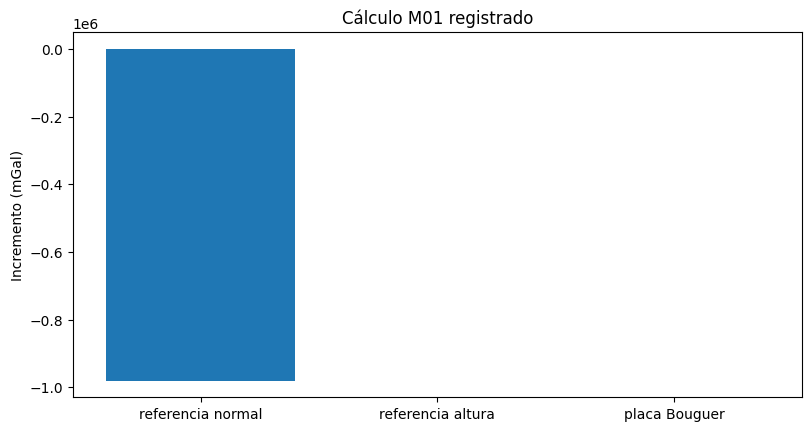

etapas: ['normal_reference', 'elevation_reference', 'bouguer_plate']


In [8]:
# Extraer incrementos ordenados y graficar contribuciones físicas reales.
history = conservative_result['dataset']['history']
increments = [record['additions_mgal'][0] for record in history]
fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
ax.bar(['referencia normal', 'referencia altura', 'placa Bouguer'], increments)
ax.set(ylabel='Incremento (mGal)', title='Cálculo M01 registrado')
plt.show()
print('etapas:', [record['name'] for record in history])

La cascada usa historial real del procesador: referencia y placa aparecen separadas, seguidas del valor derivado. Expone la contribución física de cada operación en vez de ocultarla en una anomalía final. No es perfil observado y carece de estructura horizontal porque el control analítico contiene una estación.

Separar perturbación física de agregación de incertidumbre. La figura usa salidas reales del procesador.

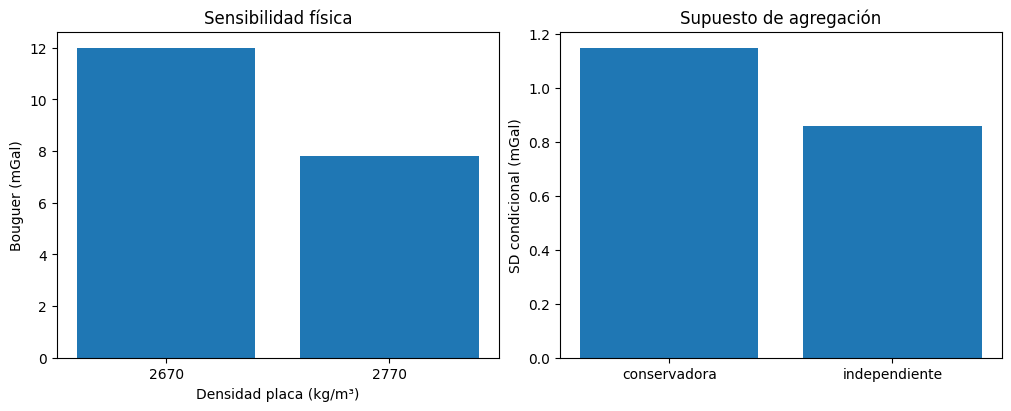

In [9]:
# Comparar cambio de densidad e incertidumbre desde ejecuciones distintas.
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
ax.bar(['2670', '2770'], [conservative_result['qc']['derived_mgal'][0],
                         denser_plate_result['qc']['derived_mgal'][0]])
ax.set(xlabel='Densidad placa (kg/m³)', ylabel='Bouguer (mGal)', title='Sensibilidad física')
bx.bar(['conservadora', 'independiente'],
       [conservative_result['processing']['uncertainty_mgal'][0],
        independent_result['processing']['uncertainty_mgal'][0]])
bx.set(ylabel='SD condicional (mGal)', title='Supuesto de agregación')
plt.show()
density_effect = denser_plate_result['qc']['derived_mgal'][0] - conservative_result['qc']['derived_mgal'][0]

La comparación procede de dos ejecuciones con fuente y configuración física iguales; solo cambia la política de agregación nombrada. La figura muestra su efecto numérico en esta estación. No determina cuál política es empíricamente correcta, no cuantifica covarianza ni incluye incertidumbre omitida de geometría y terreno.

## Resultados

**Respuesta:** Bouguer calculado es 12.000000000024315 mGal; aumentar densidad 100 kg/m³ lo cambia −4.193586369570852 mGal. SD condicionales: 1.148909022890369 y 0.8604422289723038 mGal; se rechaza repetir la corrección.

In [10]:
# Reunir resultados calculados y verificar rechazo observado.
print({'bouguer_mgal': conservative_result['qc']['derived_mgal'][0],
       'efecto_densidad_mgal': density_effect,
       'sd_conservadora_mgal': conservative_result['processing']['uncertainty_mgal'][0],
       'sd_independiente_mgal': independent_result['processing']['uncertainty_mgal'][0],
       'duplicado_rechazado': bool(duplicate_refusal)})

{'bouguer_mgal': 12.000000000024315, 'efecto_densidad_mgal': -4.193586369570852, 'sd_conservadora_mgal': 1.148909022890369, 'sd_independiente_mgal': 0.8604422289723038, 'duplicado_rechazado': True}


## Resumen

M01 es una transformación tipada y ordenada que conserva procedencia y supuestos de error. Este control demuestra admisión, referencia WGS84, placa, sensibilidad de política y rechazo de estado duplicado. El éxito valida aritmética sintética declarada, no aptitud de campo.

## Referencias

- https://pubs.usgs.gov/tm/02/d04/tm2d4.pdf
- https://www.fatiando.org/harmonica/latest/api/index.html